# 09.4 · Attention and the Transformer, explained with a 4-word sentence

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/04-attention-transformers/lesson.ipynb)

Read the [README](README.md) first and do the *broken* row on paper. This notebook repeats it, does all four words at once, adds the causal mask, and then looks inside a real Transformer.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

## 1. The hand example: *broken* attends to every word

In [2]:
words = ["the", "mug", "was", "broken"]
Q = np.array([[0, 1], [1, 0], [0, 1], [1, 1]], dtype=float)
K = np.array([[1, 0], [0, 2], [1, 0], [0, 1]], dtype=float)
V = np.array([[1, 0], [0, 4], [1, 0], [2, 2]], dtype=float)

def softmax(scores):
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

d_k = K.shape[1]
scores = Q[3] @ K.T / np.sqrt(d_k)                      # broken's query against every key
weights = np.exp(scores) / np.exp(scores).sum()
print("scores :", {w: float(v) for w, v in zip(words, scores.round(3))})
print("weights:", {w: float(v) for w, v in zip(words, weights.round(3))})
print("output :", (weights @ V).round(3))

scores : {'the': 0.707, 'mug': 1.414, 'was': 0.707, 'broken': 0.707}
weights: {'the': 0.199, 'mug': 0.403, 'was': 0.199, 'broken': 0.199}
output : [0.796 2.011]


## 2. All four words at once: three lines of matrix maths

In [3]:
S = Q @ K.T / np.sqrt(d_k)
A = softmax(S)
out = A @ V
print(pd.DataFrame(A.round(3), index=words, columns=words))
print(pd.DataFrame(out.round(3), index=words, columns=["dim 1", "dim 2"]))

          the    mug    was  broken
the     0.123  0.505  0.123   0.249
mug     0.335  0.165  0.335   0.165
was     0.123  0.505  0.123   0.249
broken  0.199  0.403  0.199   0.199
        dim 1  dim 2
the     0.744  2.519
mug     1.000  0.991
was     0.744  2.519
broken  0.796  2.011


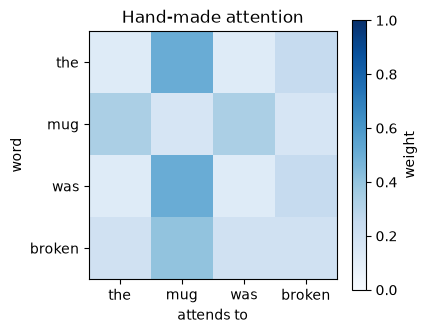

In [4]:
plt.figure(figsize=(4, 3.5))
plt.imshow(A, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(4), words); plt.yticks(range(4), words)
plt.xlabel("attends to"); plt.ylabel("word"); plt.colorbar(label="weight")
plt.title("Hand-made attention"); plt.show()

## 3. Where Q, K and V come from

In a real model nobody writes Q, K and V. Each word has an embedding $x$ (plus its position), and three learned matrices turn it into a query, key and value. Here with random numbers, just to show the shapes:

In [5]:
rng = np.random.default_rng(0)
d_model, d_head = 8, 2                       # DistilBERT: 768 and 64
X = rng.normal(size=(4, d_model))            # 4 words, one embedding each
W_Q, W_K, W_V = (rng.normal(size=(d_model, d_head)) for _ in range(3))
Q_, K_, V_ = X @ W_Q, X @ W_K, X @ W_V
print("X", X.shape, "→ Q", Q_.shape, "K", K_.shape, "V", V_.shape)
print("attention output", (softmax(Q_ @ K_.T / np.sqrt(d_head)) @ V_).shape)

X (4, 8) → Q (4, 2) K (4, 2) V (4, 2)
attention output (4, 2)


Training (08.4) adjusts $W_Q, W_K, W_V$ until the attention patterns help predict the training target.

### Positional encoding

Attention is a weighted average, so on its own it cannot tell *"mug broke the dog"* from *"dog broke the mug"*. The original Transformer adds sine and cosine waves of different lengths to each embedding:

In [6]:
def positional_encoding(n_positions, d):
    pos = np.arange(n_positions)[:, None]
    i = np.arange(d // 2)[None, :]
    angle = pos / 10000 ** (2 * i / d)
    pe = np.zeros((n_positions, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

print(pd.DataFrame(positional_encoding(4, 4).round(3), index=words))

            0      1     2    3
the     0.000  1.000  0.00  1.0
mug     0.841  0.540  0.01  1.0
was     0.909 -0.416  0.02  1.0
broken  0.141 -0.990  0.03  1.0


Each position gets a different pattern, and nearby positions get similar patterns.

## 4. The causal mask: how GPT-style models write

A decoder must not peek at words it has not written yet. Set the scores for later words to $-\infty$; softmax turns them into 0.

In [7]:
mask = np.triu(np.ones((4, 4)), k=1).astype(bool)      # True above the diagonal = "later word"
A_causal = softmax(np.where(mask, -np.inf, S))
pd.DataFrame(A_causal.round(3), index=words, columns=words)

,the,mug,was,broken
the,1.000,0.000,0.000,0.000
mug,0.670,0.330,0.000,0.000
was,0.164,0.673,0.164,0.000
broken,0.199,0.403,0.199,0.199


*the* can only see itself, *mug* sees *the* and *mug*, and only *broken* sees the whole sentence.

## 5. Inside a real Transformer: DistilBERT

In [8]:
import transformers
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert/distilbert-base-uncased",
                                 output_attentions=True, attn_implementation="eager")

def attention(sentence):
    """Tokens and attention weights: array of shape (layers, heads, tokens, tokens)."""
    enc = tokenizer(sentence, return_tensors="pt")
    att = np.stack([a[0].detach().numpy() for a in bert(**enc).attentions])
    return tokenizer.convert_ids_to_tokens(enc["input_ids"][0]), att

print(f"{sum(p.numel() for p in bert.parameters()):,} parameters, "
      f"{bert.config.n_layers} layers × {bert.config.n_heads} heads")

66,362,880 parameters, 6 layers × 12 heads


In [9]:
tokens, att = attention("the mug arrived broken so i want a refund")
print(tokens)
print("attention array:", att.shape, "(layers, heads, tokens, tokens)")
b = tokens.index("broken")
for layer in [0, 2, 5]:
    avg = att[layer, :, b, :].mean(axis=0)
    top = avg.argsort()[::-1][:3]
    print(f"layer {layer + 1}, average of heads: broken →", [(tokens[j], round(float(avg[j]), 2)) for j in top])

['[CLS]', 'the', 'mug', 'arrived', 'broken', 'so', 'i', 'want', 'a', 'ref', '##und', '[SEP]']
attention array: (6, 12, 12, 12) (layers, heads, tokens, tokens)
layer 1, average of heads: broken → [('[CLS]', 0.29), ('arrived', 0.15), ('[SEP]', 0.08)]
layer 3, average of heads: broken → [('[SEP]', 0.57), ('arrived', 0.08), ('[CLS]', 0.08)]
layer 6, average of heads: broken → [('[SEP]', 0.67), ('broken', 0.05), ('so', 0.05)]


Averaged over heads, *broken* looks mostly at the special tokens [CLS] and [SEP]. Individual heads tell a different story:

strongest broken → mug link: layer 5, head 2, weight 0.50
heads with weight above 0.1 on mug: 9 of 72


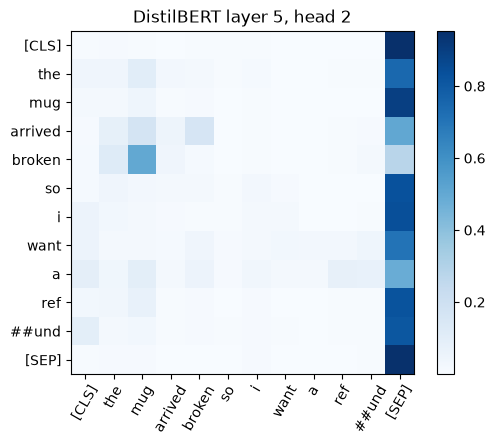

In [10]:
m = tokens.index("mug")
to_mug = att[:, :, b, m]                                  # every layer and head: broken → mug
layer, head = np.unravel_index(to_mug.argmax(), to_mug.shape)
print(f"strongest broken → mug link: layer {layer + 1}, head {head + 1}, weight {to_mug.max():.2f}")
print(f"heads with weight above 0.1 on mug: {(to_mug > 0.1).sum()} of {to_mug.size}")
plt.figure(figsize=(5.5, 4.5))
plt.imshow(att[layer, head], cmap="Blues")
plt.xticks(range(len(tokens)), tokens, rotation=60); plt.yticks(range(len(tokens)), tokens)
plt.title(f"DistilBERT layer {layer + 1}, head {head + 1}"); plt.colorbar(); plt.tight_layout(); plt.show()

A handful of heads (9 of 72 put more than 0.1 on *mug*) do what the hand example did; the strongest gives *mug* half of *broken*'s attention. The rest track other things, or park their attention on [SEP]. That is the honest picture: attention shows where information flows, but no single map explains the model's decision.

## Quiz answers

1. **Query**: what this word is looking for. **Key**: what this word offers to others. **Value**: the information it passes on when attended to.
2. Dot products grow with the vector length; without the division, scores get large, softmax saturates and puts almost all weight on one word, and training becomes unstable.
3. Attention is a weighted average and ignores order on its own; positional encoding adds each word's position to its embedding.
4. They generate text left to right and are trained to predict the next word; letting them see later words would let them copy the answer. The causal mask hides them.
5. Attention compares every token with every token, so cost and memory grow with the **square** of the length: 1,000 times more tokens means a million times more scores.

**Next:** [09.5 Hugging Face](../05-hugging-face/)